# 05 · The predictors and the drivers behind them

**Questions:** which predictors carry the risk model, and which drivers of forest loss do they stand for? Are the drivers not yet in the model worth adding?

A **driver** is why forest is lost: the activity on the ground (agriculture, wood extraction, infrastructure) and the forces behind it (Geist & Lambin 2002). A **predictor** is a mapped variable that says where loss is likely. The model uses predictors; drivers are used to choose them and to explain the loss (`studies/forest_loss_drivers.ipynb`, section 1). In Guinea, shifting cultivation causes 82 % of the loss of 2013–2024 and permanent agriculture 16 %; mining, logging, settlements and fire each under 1 % of what Hansen records (same notebook, section 5, from Sims et al. 2025).

**The improved model's 16 predictors**, each measured at the start of the window it predicts, in four groups by the kind of driver they stand for, and four others:

| Group | Predictor | Stands for | At 100 m | Reference |
|---|---|---|---|---|
| Loss history | Local loss rate (share of the forest lost within 5 km in the 3 years before) | Clearing spreads from recent clearing; fallows return to cultivation | From the shares (notebook 01) | Rosa et al. 2013 |
| | Distance to recent loss (3 years before) | Same | Same | Rosa et al. 2013 |
| | Distance to prior loss (since 2001) | Same, over a longer past | Same | Soares-Filho et al. 2002 |
| Terrain | Elevation, slope | Ease of clearing and farming; natural accessibility | SRTM, the platform's functions | Busch & Ferretti-Gallon 2017, 2023 |
| Access | Distance to roads | Infrastructure | OpenStreetMap, the platform's `process_vector_layer` | Pfaff et al. 2007; Laurance et al. 2009 |
| | Distance to built-up area | Settlements, urban expansion | GHSL built-up surface, latest epoch before the window | DeFries et al. 2010 |
| | Travel time to cities (2015) | Markets; fuelwood and charcoal demand | Weiss et al. 2018, resampled | Chomitz & Gray 1996; Ahrends et al. 2010 |
| | Population density | People who clear | WorldPop, latest year before the window | Busch & Ferretti-Gallon 2017 |
| Climate | Land-surface temperature, soil moisture (the year before the window) | Returns to farming; also warmer where land is already open | MODIS, ERA5-Land, resampled | Busch & Ferretti-Gallon 2017 |
| | Rainfall, 1991–2020 normal | Returns to farming | CHIRPS, resampled | Busch & Ferretti-Gallon 2017; WMO 2017 |
| Others | Points of interest | Settlements and services | OpenStreetMap amenities, the platform's heatmap | Weiss et al. 2018 |
| | Distance to railways | Mining (the railways serve the mines) | OpenStreetMap, the platform's function | Sonter et al. 2017 |
| | Distance to waterways | Access and transport by river | OpenStreetMap, the platform's function | Serneels & Lambin 2001 |
| | Fire history (years burned of the 5 before) | Bush fires | MODIS burned area, resampled | Dwomoh & Wimberly 2017; NERF 2026 |

**Compared with the deployed model** (notebook 03: eleven predictors, the distance to prior loss and the palm-oil price, 13 in all), every yearly layer is read at the window's start instead of 2024, the yearly rainfall is replaced by its normal, aspect and the palm-oil price are left out (notebook 09 tests the price), and the loss history, built-up area, travel time and fire history are added. The four groups follow the meta-analyses of Busch & Ferretti-Gallon (2017, 2023): deforestation is consistently higher where land is accessible (natural features such as slope and elevation, and built infrastructure such as roads, cities and cleared areas) and where returns to agriculture are higher.

**How each predictor is judged** (notebooks 04 and 06): the improved model with one change, trained on the same cells (drawn in proportion to the forest lost and kept), scored by AUC over the 30 m pixels on the same 3 million test cells, three seeds. **A change counts when it moves AUC the same way in all three windows and by more than twice the run-to-run noise (0.0034) on average.** Predictors that overlap can each be left out without loss while the group still matters (Toloşi & Lengauer 2011), so they are also tested as groups (Gregorutti et al. 2015).

The code is `scripts/model_variants.py` (one change at a time), `scripts/lean_and_ecoregions.py` (groups) and `scripts/candidates.py` (new drivers). Results are saved in `outputs/runs/`; set `RERUN = True` to compute them again (15–20 minutes per window each).

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

HERE = Path.cwd()
sys.path.insert(0, str(HERE.parent / "scripts"))
import model as MM
import model_variants as D
import lean_and_ecoregions as F
import candidates as C

%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False})
OUT = HERE.parent / "outputs" / "summary"
RERUN = False
variants = [MM.cached(D.split_name(s), lambda s=s: D.run_split(s), rerun=RERUN) for s in MM.SPLITS]
lean = [MM.cached(F.split_name(s), lambda s=s: F.run_split(s), rerun=RERUN) for s in MM.SPLITS]
new = [MM.cached(C.split_name(s), lambda s=s: C.run_split(s), rerun=RERUN) for s in MM.SPLITS]
WINDOWS = [run["split"].split(" → ")[1] for run in variants]
NOISE = np.mean([np.std(v) for run in variants for v in run["variants"].values()])


def compare(runs, base="Improved model"):
    # Change in AUC against the improved model in each test window, mean change, and the verdict.
    ref = {w: np.mean(run["variants"][base]) for w, run in zip(WINDOWS, runs)}
    rows = []
    for name in runs[0]["variants"]:
        if name == base:
            continue
        d = np.array([np.mean(run["variants"][name]) - ref[w] for w, run in zip(WINDOWS, runs)])
        if (d > 0).all() and d.mean() > 2 * NOISE:
            verdict = "Leaving it out helps" if name.startswith("Without") else "Helps"
        elif (d < 0).all() and d.mean() < -2 * NOISE:
            verdict = "Needed" if name.startswith("Without") else "Hurts"
        else:
            verdict = "No clear effect"
        rows.append({"Change": name, **dict(zip(WINDOWS, d)), "Mean change": d.mean(), "Verdict": verdict})
    return pd.DataFrame(rows).set_index("Change")

## 1 · One predictor at a time

Each of the 16 left out in turn, and each predictor tested and not kept added in turn: aspect, yearly rainfall instead of its normal, protected area, distance to mines (Maus et al. 2022), roads from GRIP4, ecoregion, night lights, distance to the forest edge. And the yearly layers read at their latest year, as the platform's hold-out does (notebook 03).

In [2]:
one = compare(variants)
one.round(4).to_csv(OUT / "05_one_at_a_time.csv")
print(f"Run-to-run noise (seed SD) {NOISE:.4f}; the bar is a mean change of {2 * NOISE:.4f}")
one.sort_values("Mean change").round(4)

Run-to-run noise (seed SD) 0.0017; the bar is a mean change of 0.0034


,2017–2019,2020–2022,2022–2024,Mean change,Verdict
Change,,,,,
Without Recent loss rate around the cell (5 km),-0.0023,-0.0197,-0.0146,-0.0122,Needed
Without Distance to recent loss,-0.0051,-0.0067,-0.0043,-0.0054,Needed
With Night lights,-0.0032,-0.0024,-0.0008,-0.0021,No clear effect
Yearly rainfall instead of the normal,-0.0042,-0.0008,-0.0003,-0.0018,No clear effect
Without Slope,-0.0008,-0.0019,-0.0021,-0.0016,No clear effect
Without Distance to prior loss,0.0006,-0.0014,-0.0022,-0.0010,No clear effect
Without Elevation,-0.0012,-0.0007,-0.0001,-0.0006,No clear effect
Without Distance to built-up area,-0.0005,-0.0009,-0.0004,-0.0006,No clear effect
Without Fire history (years burned of 5),-0.0004,-0.0005,-0.0006,-0.0005,No clear effect


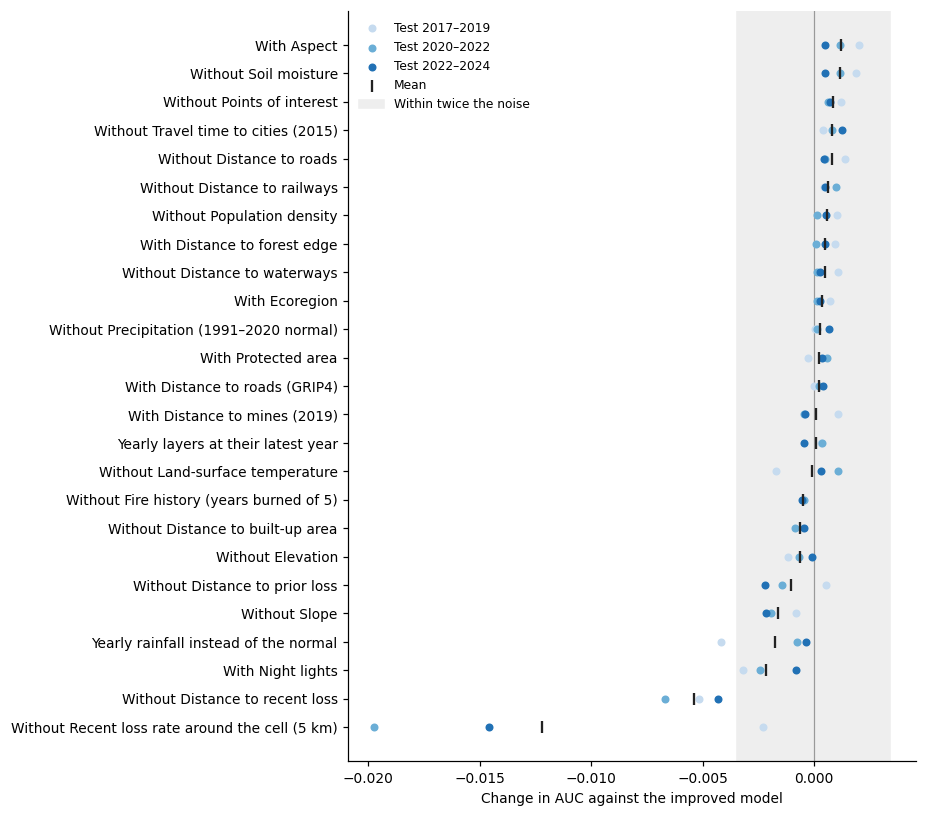

In [3]:
order = one.sort_values("Mean change").index
fig, ax = plt.subplots(figsize=(8.5, 7.5))
y = np.arange(len(order))
for w, color in zip(WINDOWS, ["#c6dbef", "#6baed6", "#2171b5"]):
    ax.scatter(one.loc[order, w], y, s=18, color=color, label=f"Test {w}", zorder=3)
ax.scatter(one.loc[order, "Mean change"], y, s=60, marker="|", color="#222", label="Mean", zorder=4)
ax.axvspan(-2 * NOISE, 2 * NOISE, color="#eeeeee", zorder=0, label="Within twice the noise")
ax.axvline(0, color="#999", lw=0.8)
ax.set_yticks(y, order); ax.set_xlabel("Change in AUC against the improved model")
ax.legend(frameon=False, loc="upper left", fontsize=8)
plt.tight_layout(); plt.show()

**Reading:**

* **Two predictors carry the model: the local loss rate and the distance to recent loss.** Leaving out the local loss rate costs 0.012 AUC (up to 0.020 in a window), and leaving out the distance to recent loss 0.005. Both clear the bar in every window. Both stand for the same driver: clearing returns where it just happened, as in a fallow cycle.
* **Each of the other 14 can be left out on its own without a clear loss.** Slope comes closest (−0.0016, lower in every window). Points of interest, roads, travel time, soil moisture and railways even do slightly better when left out, in every window (+0.0005 to +0.0012), but below the bar. The predictors overlap (rainfall, temperature and soil moisture; the distances to roads, towns and amenities), so when one goes the others carry its information. Section 2 tests them as groups.
* **None of the predictors tested and not kept helps.** Protected areas, distance to mines, GRIP4 roads, ecoregion and distance to the forest edge change AUC by under 0.001. Night lights and yearly rainfall do worse in every window. Aspect does slightly better in every window (+0.001), below the bar.
* **Reading the yearly layers at their latest year makes no difference to this model** (+0.0001), because it relies on the loss history. It does inflate the deployed model's score (notebook 03); reading every predictor at the window's start stays the correct method.

## 2 · The predictors in groups

The groups added in a fixed order, by theme (not chosen by score, which would flatter the result), on full risk maps: AUC (three seeds) and Verra's tests (first seed), as in notebook 07.

In [4]:
rows = []
for w, run in zip(WINDOWS, lean):
    for name, r in run["lean"].items():
        rows.append({"Test window": w, "Set": name, "AUC": np.mean(r["aucs"]),
                     "Fit MedAE (ha)": r["fit_medae_ha"], "Prediction MedAE (ha)": r["prediction_medae_ha"]})
groups = pd.DataFrame(rows)
groups.round(4).to_csv(OUT / "05_groups.csv", index=False)
full = groups[groups.Set == "Improved model (16)"].set_index("Test window")
groups["AUC vs improved"] = groups.AUC - groups["Test window"].map(full.AUC)
summary = groups.groupby("Set", sort=False).agg(**{
    "AUC": ("AUC", "mean"), "AUC vs improved": ("AUC vs improved", "mean"),
    "Windows below the improved model": ("AUC vs improved", lambda d: int((d < 0).sum())),
    "Fit MedAE (ha)": ("Fit MedAE (ha)", "mean"), "Prediction MedAE (ha)": ("Prediction MedAE (ha)", "mean")})
summary["Gain of the group (AUC)"] = summary.AUC.diff()
summary.round(4)

,AUC,AUC vs improved,Windows below the improved model,Fit MedAE (ha),Prediction MedAE (ha),Gain of the group (AUC)
Set,,,,,,
Loss history (3),0.7038,-0.0486,3,209.7266,256.4282,NaN
+ terrain (5),0.7283,-0.0241,3,178.8387,207.3722,0.0245
+ access (9),0.7405,-0.0119,3,148.1408,198.2505,0.0122
+ climate (12),0.7507,-0.0017,3,126.9575,166.7776,0.0102
Improved model (16),0.7524,0.0000,0,128.3138,179.5264,0.0017


**Reading:**

* **The loss history alone is not enough:** 0.704 AUC, 0.049 below the full model. Terrain adds 0.024, access 0.012 and climate 0.010, and each group clears the bar in every window. So the predictors matter as groups even though section 1 could leave any one of them out: within a group they stand in for each other, as Toloşi & Lengauer (2011) and Gregorutti et al. (2015) describe for correlated predictors in random forests.
* **The groups are the drivers of the literature:** the meta-analyses of Busch & Ferretti-Gallon (2017, 2023) find deforestation consistently higher where land is accessible (terrain, roads, settlements, cleared areas) and where farming pays (climate).
* **Twelve predictors do as well as sixteen.** Without points of interest, railways, waterways and fire history, AUC is 0.0017 lower (below the full model in every window, but under the bar of 0.0034). Verra's errors are about the same: fit 127 against 128 ha, prediction 167 against 180 ha, better in some windows and worse in others.
* **Verra's errors move by 10–30 ha with the seed alone.** The full model here (one seed) differs from the same model in notebook 07 (another draw of training cells) by that much, so differences of that size between sets mean nothing.

## 3 · Drivers not yet in the model

The drivers named by the project's concept note, Guinea's reference level (NERF 2026) or the literature with no predictor yet (`studies/forest_loss_drivers.ipynb`, section 3), tested here when a map exists:

| Candidate | Driver it stands for | Data | When |
|---|---|---|---|
| Cropland within 5 km; distance to cropland (cells at least half cropland) | Agricultural expansion, the main driver | GLAD global land cover and land use, cropland class (Potapov et al. 2022): annual and perennial herbaceous crops with fallows up to 4 years; longer shifting cultivation is not cropland there | 2010, 2015, 2020 |
| Regrown forest within 5 km | The fallow cycle: forest cleared since 2000 that has grown back to trees of 5 m or more, the next to be cleared | The same product's tree height, on Hansen forest of 2000 lost at least 5 years before | 2010, 2015, 2020 |
| Staple crop suitability | Returns to farming | FAO GAEZ v4 (Fischer et al. 2021), rain-fed, low inputs, 1981–2010 climate: the best of upland rice, cassava, maize and groundnut, ~9 km | Static |
| Oil palm suitability | A cash crop | Same, oil palm | Static |

Each window reads the latest map at or before its start (a window starting in 2018 reads 2015). Data are direct downloads, no Earth Engine (`scripts/candidates.py`; 30 m maps summed onto the 100 m grid as shares). Already tested in section 1 and not kept: protected areas, mines, GRIP4 roads, night lights; the palm-oil price in notebook 09. Not testable with a map: land zoning and development plans, the mining cadastre (to request from the ministries), poverty, tenure and governance (not mappable at 100 m).

In [5]:
cand = compare(new)
cand.round(4).to_csv(OUT / "05_new_drivers.csv")
print(f"Improved model: AUC {np.mean([np.mean(r['variants']['Improved model']) for r in new]):.4f} on the test cells; bar {2 * NOISE:.4f}")
cand.round(4)

Improved model: AUC 0.7529 on the test cells; bar 0.0034


,2017–2019,2020–2022,2022–2024,Mean change,Verdict
Change,,,,,
With Cropland within 5 km,0.0007,0.0003,0.0001,0.0003,No clear effect
With Distance to cropland,0.0008,-0.0001,-0.0002,0.0002,No clear effect
With Regrown forest within 5 km,-0.0005,-0.0001,-0.0011,-0.0006,No clear effect
With Staple crop suitability (GAEZ),-0.0002,-0.0001,-0.0001,-0.0001,No clear effect
With Oil palm suitability (GAEZ),0.0005,0.0005,0.0003,0.0005,No clear effect
With all five,0.0014,0.0002,-0.0006,0.0003,No clear effect


In [6]:
imp = pd.DataFrame([run["importance"] for run in new]).mean().sort_values(ascending=False)
print("Importance with all five added (random forest, first seed, mean of the windows)")
imp.rename("Importance").to_frame().round(3)

Importance with all five added (random forest, first seed, mean of the windows)


,Importance
Recent loss rate around the cell (5 km),0.193
Land-surface temperature,0.079
Precipitation (1991–2020 normal),0.062
Staple crop suitability (GAEZ),0.058
Distance to built-up area,0.055
Distance to recent loss,0.053
Soil moisture,0.052
Elevation,0.046
Slope,0.045
Regrown forest within 5 km,0.043


**Reading:**

* **None of the new drivers improves the model.** Every change is within ±0.0015 AUC in every window, far under the bar of 0.0034. Oil palm suitability and cropland within 5 km are slightly higher in all three windows (+0.0005 and +0.0003 on average), a seventh and a tenth of the bar. Regrown forest is slightly lower in all three. All five together: +0.0014, +0.0002, −0.0006.
* **Staple crop suitability takes a large share of the importance (0.058, fourth) but adds nothing.** It is a climate and soil map at about 9 km, so it repeats what the rainfall normal and the land temperature already tell the model. Importance shares out what overlapping predictors carry; it does not say what each adds.
* **Why cropland and regrowth add little:**
  * **Cropland** is about 1 % of Guinea (0.17–0.32 million ha in 2010–2020), because the map counts permanent fields and leaves out shifting cultivation with fallows over 4 years: 82 % of the loss. Where permanent fields are, the loss history and the access predictors already are.
  * **Regrown forest** (Hansen forest lost at least 5 years earlier and back to trees of 5 m or more) is 0.07–0.44 million ha, read every 5 years. The local loss rate and the distance to prior loss already mark the same fallow landscape, every year.

## 4 · The drivers and the predictors that stand for them

| Driver (share of Guinea's loss, 2013–2024) | Predictors that stand for it | What it carries here |
|---|---|---|
| **Shifting cultivation** (82 %; NERF: *extension agricole*) | Local loss rate, distance to recent and prior loss; regrown forest (tested) | The most: the loss history alone gives AUC 0.704, and the local loss rate and the distance to recent loss are the only predictors needed one by one. Regrown forest adds nothing beyond them |
| **Permanent agriculture** (16 %) | Climate (rainfall normal, land temperature, soil moisture), terrain; cropland and crop suitability (tested) | Climate adds 0.010 and terrain 0.024 as groups. Cropland and suitability add nothing beyond them |
| **Fuelwood and charcoal, settlements** (NERF: *bois énergie*, *extension urbaine*; under 1 % mapped as settlements) | Travel time to cities, distance to built-up area, population, points of interest | The access group adds 0.012 |
| **Infrastructure** | Distance to roads (OpenStreetMap; GRIP4 tested) | Part of the access group; no single road layer is needed |
| **Mining** (hard commodities, 0.6 %; NERF: *activités minières*, *orpaillage*) | Distance to railways; distance to mines (tested) | Neither needed. Keep mining as a scenario layer (concessions) rather than a risk predictor |
| **Bush fires** (NERF: *feux de brousse*; ~0 % as Hansen loss) | Fire history | Not needed on its own; savanna fires burn grass, not the trees Hansen maps |
| **Logging** (0.4 %) | None | Selective logging leaves the canopy, so Hansen records little of it |
| **Protection** (lowers loss) | Protected area (tested) | No effect on the ranking |
| **Underlying: population, poverty, tenure, governance** | Population density; the rest not mappable at 100 m | Report per prefecture as context, not as predictors |
| **Policy: zoning and development plans** | None (to request from the ministries) | For scenarios, not for the risk model |

## 5 · What this means

* **The model is carried by the loss history**, the predictors that stand for shifting cultivation, the driver of 82 % of Guinea's loss. Terrain, access and climate add to it as groups, as the literature's accessibility and returns-to-agriculture drivers.
* **Use the 16 predictors.** Twelve (without points of interest, railways, waterways and fire history) do about the same: AUC 0.0017 lower in every window, under the noise bar, and Verra's errors better in some windows and worse in others. The 16 are kept because they rank the next loss higher in every window.
* **Do not add the new drivers.** Cropland, regrown forest, staple crop and oil palm suitability were tested with open data (no Earth Engine) and none improves the model. Mining, protected areas, roads from GRIP4, night lights and the palm-oil price were tested earlier with the same result.
* **Recommended for later, as data rather than predictors:**
  * **A cropland map that includes shifting cultivation's fallows.** GLAD's cropland (section 3) leaves out fallows over 4 years, where 82 % of the loss happens.
  * **A forest map every year**, to tell regrowth from standing forest between Hansen's loss years. Land cover could give one, but not yet reliably: Esri's yearly tree class does not follow Hansen's ≥ 30 % canopy definition, and it changes 10–15 % of Guinea a year, a third of which flips back the next year (`studies/dataset_checks/01_desk_check`). GLAD's map is every 5 years (the regrown-forest test of section 3). TMF (JRC) is yearly but covers only the moist forest, 3.4 % of Guinea.
* **Next, notebook 06:** one national model or one per ecoregion.